In [1]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import xarray as xr
import sys
import matplotlib.pyplot as plt
from pathlib import Path
import glob
sys.path.append(str(Path("../src").resolve()))
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.align import align_to_reference_time

## WHICH DAY /DATASET

In [2]:
Dataset_94GHz = "20230930_94GHz"
Dataset_35GHz = "20230930_35GHz"
Processed_Dataset = "20230930"

Load Both Radars

In [4]:
# Cell 2 — Load both
def load_rpg(folder):
    files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))
    ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03
    epoch = pd.Timestamp("2001-01-01")
    ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
    ds = drop_duplicate_times(ds)
    return ds

ds_w  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")
ds_ka = load_rpg(f"../data/raw/cmtrace/{Dataset_35GHz}")

KeyboardInterrupt: 

In [ ]:
import time
files = sorted(glob.glob(str(Path("../data/raw/cmtrace/20230928") / "*ZEN.LV1.nc")))
t0 = time.time()
ds = xr.open_mfdataset(files, combine="by_coords")
print(time.time()-t0)

247.4953579902649


In [ ]:
t0 = time.time()
epoch = pd.Timestamp("2001-01-01")
ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
print(time.time()-t0)

0.18619894981384277


C:\Users\geron\AppData\Local\Temp\ipykernel_18548\2776936307.py:3: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))


In [ ]:
t0 = time.time()
ds = drop_duplicate_times(ds)
print(time.time()-t0)

8.142892837524414


In [5]:
def load_rpg(folder, keep_extra=()):
    files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))

    per_chirp = ["ZE", "MeanVel", "SLv", "SLh"]
    wanted = {f"C{c}{v}" for c in (1, 2, 3) for v in per_chirp}
    wanted |= {f"C{c}Range" for c in (1, 2, 3)}
    wanted |= {
        "Time",
        "TProf", "TAlts",     # temperature profile + its real altitude grid
        "AHProf", "HAlts",    # absolute humidity profile + its real altitude grid
        "SurfPres",           # surface pressure
        "LWP",                # liquid water path
    }
    wanted |= set(keep_extra)

    with xr.open_dataset(files[0]) as probe:
        available = set(probe.variables)
    drop = sorted(available - wanted)

    ds = xr.open_mfdataset(
        files,
        combine="by_coords",
        drop_variables=drop,
        parallel=True,
        chunks={"Time": 500},
    )
    epoch = pd.Timestamp("2001-01-01")
    ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))

    return drop_duplicate_times(ds)

ds_w  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")
ds_ka = load_rpg(f"../data/raw/cmtrace/{Dataset_35GHz}")

C:\Users\geron\AppData\Local\Temp\ipykernel_24408\588926849.py:28: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
C:\Users\geron\AppData\Local\Temp\ipykernel_24408\588926849.py:28: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 

In [ ]:
with xr.open_dataset(sorted(glob.glob("../data/raw/cmtrace/20230928/*ZEN.LV1.nc"))[0]) as p_w:
    print("W DualPol:", p_w.DualPol.values)
with xr.open_dataset(sorted(glob.glob("../data/raw/cmtrace/20230928_KaBand/*ZEN.LV1.nc"))[0]) as p_ka:
    print("Ka DualPol:", p_ka.DualPol.values)

W DualPol: np.bytes_(b'\x02')
Ka DualPol: np.bytes_(b'\x02')


In [31]:
print(ds_ka.variables)

Frozen({'TAlts': <xarray.Variable (Time: 26898, TAlt: 93)> Size: 10MB
dask.array<getitem, shape=(26898, 93), dtype=float32, chunksize=(78, 93), chunktype=numpy.ndarray>
Attributes:
    Name:     Temperature profile altitude layers
    Units:    m, 'HAlts': <xarray.Variable (Time: 26898, HAlt: 93)> Size: 10MB
dask.array<getitem, shape=(26898, 93), dtype=float32, chunksize=(78, 93), chunktype=numpy.ndarray>
Attributes:
    Name:     Humidity profile altitude layers
    Units:    m, 'SurfPres': <xarray.Variable (Time: 26898)> Size: 108kB
dask.array<getitem, shape=(26898,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Attributes:
    Name:     Surface atmospheric pressure from weather station
    Units:    hPa, 'LWP': <xarray.Variable (Time: 26898)> Size: 108kB
dask.array<getitem, shape=(26898,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Attributes:
    Name:     Liquid water path
    Units:    g/m^2, 'TProf': <xarray.Variable (Time: 26898, TAlt: 93)> Size: 10MB


Reflectivities

In [32]:
# Cell 3 — Reflectivities
ze_w  = get_reflectivity(ds_w)
ze_ka = get_reflectivity(ds_ka)

Ranges and Time Coverage

In [33]:
# Cell 4 — Inspect ranges & time coverage  ← KEEP, condensed
print(f"W : {ze_w['range'].values[0]:.1f} → {ze_w['range'].values[-1]:.1f} m  ({ze_w.sizes['range']} gates)")
print(f"Ka: {ze_ka['range'].values[0]:.1f} → {ze_ka['range'].values[-1]:.1f} m  ({ze_ka.sizes['range']} gates)")
identical = np.allclose(ze_w['range'].values, ze_ka['range'].values)
print(f"Ranges identical: {identical}")

# Time coverage
print(f"\nW  : {ze_w.Time.values[0]}  →  {ze_w.Time.values[-1]}  ({ze_w.sizes['Time']} samples)")
print(f"Ka : {ze_ka.Time.values[0]}  →  {ze_ka.Time.values[-1]}  ({ze_ka.sizes['Time']} samples)")

# Temporal resolution
dt_ka = (ze_ka.Time.diff("Time") / np.timedelta64(1,"s")).median().values
dt_w  = (ze_w.Time.diff("Time")  / np.timedelta64(1,"s")).median().values
print(f"\nMedian Δt  W={dt_w:.1f}s   Ka={dt_ka:.1f}s")


W : 111.8 → 11974.8 m  (339 gates)
Ka: 111.8 → 11974.8 m  (339 gates)
Ranges identical: True

W  : 2023-09-30T12:01:16.000000000  →  2023-10-01T05:59:32.000000000  (26898 samples)
Ka : 2023-09-30T12:01:16.000000000  →  2023-10-01T05:59:32.000000000  (26898 samples)

Median Δt  W=1.0s   Ka=1.0s


In [34]:
missing_in_w = np.setdiff1d(ze_ka["Time"].values, ze_w["Time"].values)

print(f"Missing in W: {len(missing_in_w)} time steps")
print(missing_in_w)

Missing in W: 1 time steps
['2023-10-01T03:24:17.000000000']


==================================================================================================================================================

ALIGN TIME

==================================================================================================================================================

In [35]:
# Cell 5 — Common time grid  --> If it is more then a little part that is missing for the time steps

# ze_w_c = align_to_reference_time(
    #da_ref=ze_ka,
    #da_target=ze_w,
    #method="nearest"
#)

#ze_ka_c = ze_ka

In [36]:
# Cell 6 — Range alignment (only if not identical)
#if not identical:
 # ze_ka_c = ze_ka_c.interp(range=ze_w_c["range"])

In [37]:
print(len(ze_w.Time))
print(len(ze_ka.Time))

26898
26898


In [38]:
common_times = np.intersect1d(ze_w.Time.values, ze_ka.Time.values)

print(f"W-band times : {len(ze_w.Time)}")
print(f"Ka-band times: {len(ze_ka.Time)}")
print(f"Common times : {len(common_times)}")

W-band times : 26898
Ka-band times: 26898
Common times : 26897


In [39]:
missing_in_ka = np.setdiff1d(ze_w.Time.values, ze_ka.Time.values)
missing_in_w  = np.setdiff1d(ze_ka.Time.values, ze_w.Time.values)

print("Missing in Ka:", missing_in_ka)
print("Missing in W :", missing_in_w)

Missing in Ka: ['2023-09-30T20:00:32.000000000']
Missing in W : ['2023-10-01T03:24:17.000000000']


In [40]:
common_times = np.intersect1d(ze_w.Time.values, ze_ka.Time.values)

ze_w_c = ze_w.sel(Time=common_times)
ze_ka_c = ze_ka.sel(Time=common_times)

In [41]:
# Cell 7 — Verify
print(f"After alignment: W={ze_w_c.shape}, Ka={ze_ka_c.shape}")
assert ze_w_c.shape == ze_ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(26897, 339), Ka=(26897, 339)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

PLOT

==================================================================================================================================================

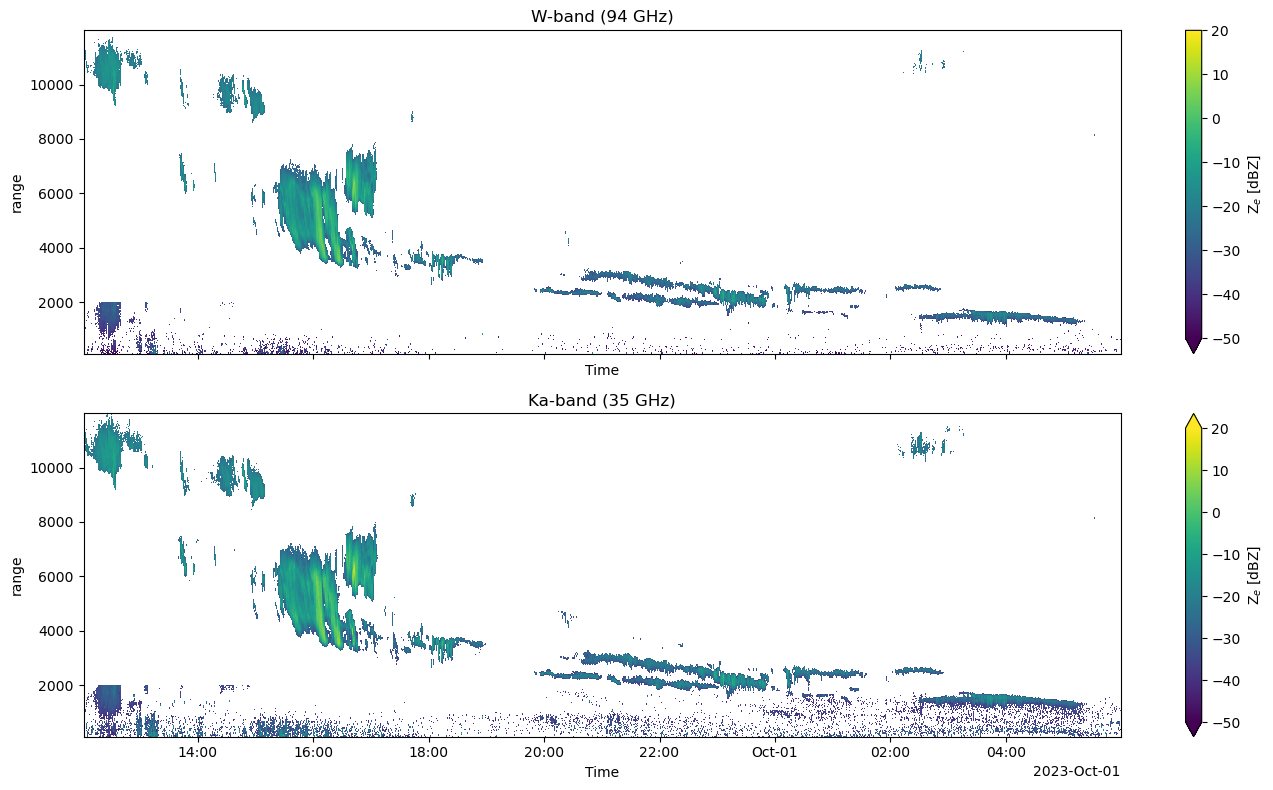

In [42]:
# Cell 8 — Side-by-side plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
ze_w_c.plot(x="Time", y="range", ax=axes[0], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[0].set_title("W-band (94 GHz)")
ze_ka_c.plot(x="Time", y="range", ax=axes[1], cmap="viridis", vmin=-50, vmax=20, cbar_kwargs={"label": "Z$_e$ [dBZ]"})
axes[1].set_title("Ka-band (35 GHz)")
plt.tight_layout()
plt.show()

(array([3.0000e+00, 1.1000e+01, 1.4000e+01, 1.1000e+01, 1.3000e+01,
        2.6000e+01, 3.7000e+01, 4.2000e+01, 7.0000e+01, 1.3300e+02,
        4.4400e+02, 1.6400e+03, 3.5790e+03, 6.2190e+03, 9.4160e+03,
        1.2652e+04, 1.5604e+04, 1.7753e+04, 1.9232e+04, 2.0268e+04,
        2.0061e+04, 1.9994e+04, 2.0005e+04, 1.9510e+04, 1.9110e+04,
        1.8583e+04, 1.8276e+04, 1.8196e+04, 1.8291e+04, 1.8548e+04,
        1.8640e+04, 1.8395e+04, 1.8234e+04, 1.8345e+04, 1.8506e+04,
        1.9493e+04, 2.0578e+04, 2.1253e+04, 2.1558e+04, 2.1419e+04,
        2.0712e+04, 2.0041e+04, 1.8883e+04, 1.7726e+04, 1.6447e+04,
        1.5479e+04, 1.4749e+04, 1.4201e+04, 1.3656e+04, 1.2918e+04,
        1.3194e+04, 1.2457e+04, 1.1060e+04, 9.6260e+03, 8.7390e+03,
        8.0310e+03, 7.3880e+03, 6.4130e+03, 4.9590e+03, 4.0560e+03,
        3.2880e+03, 2.8320e+03, 2.7280e+03, 2.6910e+03, 2.9000e+03,
        3.0350e+03, 3.0100e+03, 2.8620e+03, 2.6680e+03, 2.4310e+03,
        1.9720e+03, 1.3880e+03, 1.2790e+03, 1.29

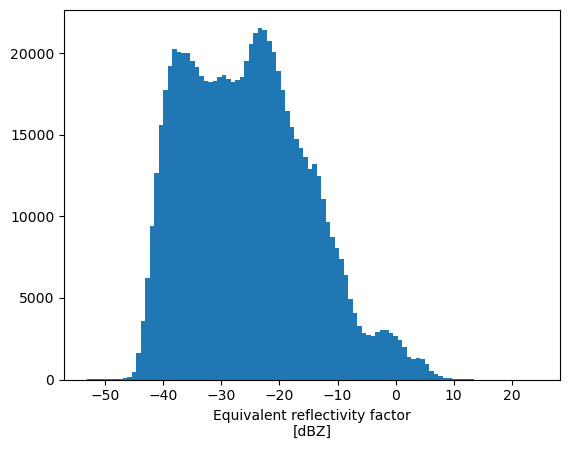

In [43]:
ze_ka.plot.hist(bins=100)

TEMPERATURE

In [44]:
T = ds_w["TProf"]                     # whatever the variable is named
print("Shape:", T.shape)                 # (Time, TAlt)?
print("Dims:", T.dims)
print("Min/Max:", float(T.min()), float(T.max()))
print("First profile (first time, all altitudes):")
print(T.isel(Time=0).values)
print("Altitude coord (if any):")
print(ds_w.coords)  # look for TAltLayer or similar


Shape: (26898, 93)
Dims: ('Time', 'TAlt')
Min/Max: 227.70535278320312 291.97088623046875
First profile (first time, all altitudes):
[291.78265 291.61084 291.3764  291.0228  290.6294  290.321   289.9748
 289.6502  289.3312  289.01248 288.6978  288.38702 288.07462 287.75714
 287.43686 287.11426 286.79416 286.47253 286.15225 285.8391  285.43265
 285.03918 284.6482  284.25833 283.8829  283.53043 283.191   282.85764
 282.53586 282.23718 281.96362 281.6994  281.44424 281.19678 280.96484
 280.7627  280.57993 280.3143  280.06683 279.8377  279.65665 279.4948
 279.34827 279.214   279.0829  278.96216 278.83716 278.666   278.50183
 278.11832 277.91724 277.6815  277.4553  277.2589  276.97015 276.66544
 276.32446 275.97354 275.6213  275.2673  274.88934 274.49002 274.08655
 273.6768  273.03012 272.3389  271.64404 270.9106  270.15442 269.3968
 268.6299  268.3645  267.2646  266.1498  265.0175  263.84442 262.701
 261.511   260.25775 258.3639  256.39252 254.37256 252.3217  250.15904
 247.97911 245.71028 

==================================================================================================================================================

The T Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Temperature Profile in T_Alts, because Temperature Profile T_Prof only has Indices 1,2,3,.... Afterwards T_Prof uses T_Alts Altitudes and then the Values are interpolated onto the range grid

==================================================================================================================================================

In [45]:
# Physical altitude of radiometer profile
T_alts = ds_w["TAlts"].isel(Time=0).values
assert np.allclose(ds_w["TAlts"].values, T_alts), "TAlts varies in time!"   # T_Alts is only at time 0 and it is compared to all the rest of data in TAlts. If it is not the same, then it will raise an error. This is to ensure that the altitude values are consistent across all time steps.

# Tell xarray these are the heights of TProf  --> I give T_Prof new Altitude Values because it just as 1,2,3,4... as indice instead of actual heights
T_prof = ds_w["TProf"].assign_coords(TAlt=("TAlt", T_alts))

# Interpolate onto radar gates
T_on_range = T_prof.interp(
    TAlt=ze_w_c["range"],
    method="linear"
)

T_on_range.name = "T_cloud"

In [46]:
print(T_on_range.shape)                                # should match ze_w_c.shape
print(f"{float(T_on_range.min()):.1f} → {float(T_on_range.max()):.1f} °K")
# Expect roughly: -60 → +20 °C  for Cabauw autumn

(26898, 339)
227.9 → 290.5 °K


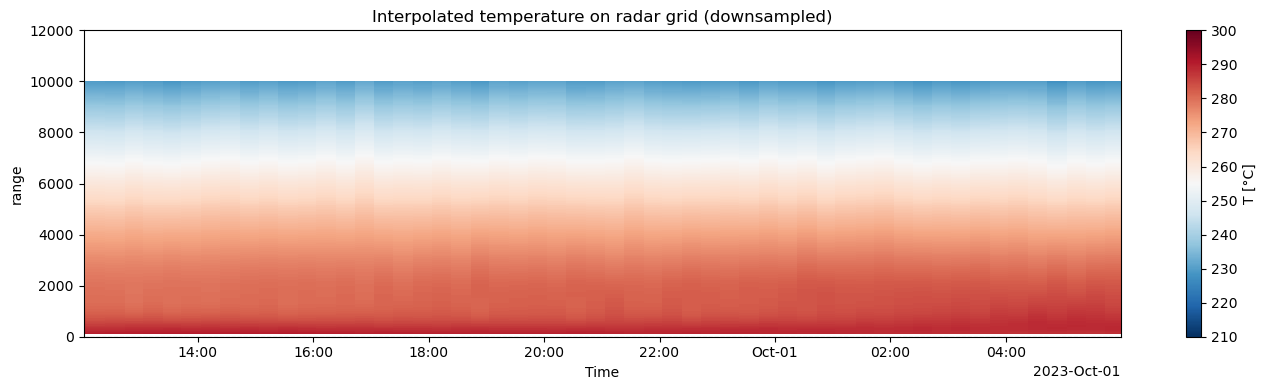

In [47]:

fig, ax = plt.subplots(1, 1, figsize=(14, 4))

T_on_range.isel(Time=slice(0, None, 5)).plot(
    x="Time",
    y="range",
    ax=ax,
    cmap="RdBu_r",
    vmin=210,
    vmax=300,
    cbar_kwargs={"label": "T [°C]"},
)

ax.axhline(0, ls="--", c="k", lw=0.8, alpha=0.5)
ax.set_ylim(0, 12000)
ax.set_title("Interpolated temperature on radar grid (downsampled)")

plt.tight_layout()
plt.show()


HUMIDITY FOR DATA SAVING

The AH Profile Values are interpolated onto the Range grid. First we have to get the altitudes for the Humidity Profile in HAlts, because Humidity Profile AHProf only has Indices 1,2,3,.... in HAlt.       Afterwards AH_Prof uses HAlts Altitudes and then the Values are interpolated onto the range grid

In [48]:
AH_alts = ds_w["HAlts"].isel(Time=0).values
assert np.allclose(ds_w["HAlts"].values, AH_alts), "HAlts varies in time!"   # AH_Alts is only at time 0 and it is compared to all the rest of data in HAlts. If it is not the same, then it will raise an error. This is to ensure that the altitude values are consistent across all time steps.

# Tell xarray these are the heights of AHProf  --> I give H_Prof new Altitude Values because it just as 1,2,3,4... as indice instead of actual heights
AH_prof = ds_w["AHProf"].assign_coords(HAlt=("HAlt", AH_alts))      #  HAlt gets new name which is the same as the original HAlts, but now it is assigned to the real Altitude variables.

# Interpolate onto radar gates
AH_on_range = AH_prof.interp(
    HAlt=ze_w_c["range"],
    method="linear"
)


AH_on_range.name = "AH_cloud"

In [49]:
print(AH_on_range)
print(AH_on_range.dims)
print(AH_on_range.shape)

<xarray.DataArray 'AH_cloud' (Time: 26898, range: 339)> Size: 36MB
dask.array<chunked_aware_interpnd, shape=(26898, 339), dtype=float32, chunksize=(78, 339), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 215kB 2023-09-30T12:01:16 ... 2023-10-01T0...
    HAlt     (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
  * range    (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
Attributes:
    Name:     Absolute humidity profiles from RPG radiometer
    Units:    g/m^3
('Time', 'range')
(26898, 339)


LWP FOR DATA SAVING

In [50]:
lwp = ds_w["LWP"]  # adjust name if needed
print(lwp)

<xarray.DataArray 'LWP' (Time: 26898)> Size: 108kB
dask.array<getitem, shape=(26898,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 215kB 2023-09-30T12:01:16 ... 2023-10-01T0...
Attributes:
    Name:     Liquid water path
    Units:    g/m^2


PRESSURE FOR DATA SAVING

In [51]:
p_surf = ds_w["SurfPres"]
print(p_surf)
print(p_surf.shape)

<xarray.DataArray 'SurfPres' (Time: 26898)> Size: 108kB
dask.array<getitem, shape=(26898,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 215kB 2023-09-30T12:01:16 ... 2023-10-01T0...
Attributes:
    Name:     Surface atmospheric pressure from weather station
    Units:    hPa
(26898,)


exponential atmosphere (constant scale height)

In [53]:
# Surface pressure (hPa)
surface_pressure = ds_w["SurfPres"].sel(Time=common_times).values

# Radar heights (m)
radar_range = ze_w_c["range"].values

# Create an empty array for the pressure profile
pressure_profile = np.zeros((len(ze_w_c.Time), len(ze_w_c.range)))

# Atmospheric scale height (m)
scale_height = 8000.0     #H=R_d*​T/g​       8000 for T= 273K ; At 288 K --> H=8427 m     ; At 250 K --> H=7310 m          Couple % difference and more in higher regions of clouds. In lower just a few % difference.

# Loop over all time steps
for t in range(len(surface_pressure)):

    # Surface pressure at this time
    p0 = surface_pressure[t]

    # Loop over all radar gates
    for r in range(len(radar_range)):

        height = radar_range[r]

        pressure_profile[t, r] = p0 * np.exp(-height / scale_height)

# Convert to xarray
P_cloud = xr.DataArray(
    pressure_profile,
    coords={
        "Time": ze_w_c["Time"],
        "range": ze_w_c["range"]
    },
    dims=("Time", "range"),
    name="P_cloud"
)

P_cloud.attrs["units"] = "hPa"
P_cloud.attrs["long_name"] = "Pressure profile"

In [54]:
print(P_cloud)
print(P_cloud.dims)
print(P_cloud.shape)

<xarray.DataArray 'P_cloud' (Time: 26897, range: 339)> Size: 73MB
array([[1011.86053467, 1009.03643799, 1006.22021484, ...,  231.84762573,
         230.75883484,  229.67520142],
       [1011.86053467, 1009.03643799, 1006.22021484, ...,  231.84762573,
         230.75883484,  229.67520142],
       [1011.86053467, 1009.03643799, 1006.22021484, ...,  231.84762573,
         230.75883484,  229.67520142],
       ...,
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064],
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064],
       [1008.21191406, 1005.39801025, 1002.59197998, ...,  231.0116272 ,
         229.92675781,  228.84703064]], shape=(26897, 339))
Coordinates:
  * Time     (Time) datetime64[ns] 215kB 2023-09-30T12:01:16 ... 2023-10-01T0...
  * range    (range) float32 1kB 111.8 134.2 156.5 ... 1.194e+04 1.197e+04
Attributes:
    units:      hPa
    long_name:  Pressure pro

Hypsometric Equation

In [55]:
# # Physical constants
# g = 9.80665          # m/s²
# R_d = 287.05         # J/(kg K)

# # Surface pressure (hPa)
# surface_pressure = ds_w["SurfPres"]

# # Radar heights (m)
# radar_range = ze_w_c["range"].values

# # Temperature on the radar grid (K)
# temperature = T_on_range.values

# # Create an empty array
# pressure_profile = np.zeros(
#     temperature.shape,
#     dtype=np.float32
# )

# # Loop over every radar profile
# for t in range(len(surface_pressure)):

#     # Pressure at the first radar gate
#     pressure_profile[t, 0] = surface_pressure.values[t]

#     # Loop upward through the atmosphere
#     for r in range(1, len(radar_range)):

#         # Height difference between two radar gates
#         dz = radar_range[r] - radar_range[r - 1]

#         # Mean temperature between the two gates
#         T_mean = 0.5 * (
#             temperature[t, r] +
#             temperature[t, r - 1]
#         )

#         # Pressure at the current gate
#         pressure_previous = pressure_profile[t, r - 1]

#         # Hypsometric equation
#         pressure_profile[t, r] = (
#             pressure_previous *
#             np.exp(-g * dz / (R_d * T_mean))
#         )

# # Convert to xarray
# P_cloud = xr.DataArray(
#     pressure_profile,
#     coords={
#         "Time": ze_w_c["Time"],
#         "range": ze_w_c["range"]
#     },
#     dims=("Time", "range"),
#     name="P_cloud"
# )

# P_cloud.attrs["units"] = "hPa"
# P_cloud.attrs["long_name"] = "Pressure profile"

Mean Doppler Velocities

In [56]:
# %% Combine MeanVel chirps (01_data_loading or wherever ZE combine happens)
MeanVel_W  = combine_chirps(ds_w,  var_prefix="MeanVel")
MeanVel_Ka = combine_chirps(ds_ka, var_prefix="MeanVel")

In [57]:
print(MeanVel_W.shape)
print(MeanVel_Ka.shape)

(26898, 339)
(26898, 339)


In [59]:
MeanVel_Ka_c = MeanVel_Ka.sel(Time=common_times)      # Both are set to the common  time ; .sel selects only the data whose Time coordinates match the Time coordinates of ze_w.
MeanVel_W_c = MeanVel_W.sel(Time=common_times)

In [60]:
print(f"After alignment: W={MeanVel_W_c.shape}, Ka={MeanVel_Ka_c.shape}")
assert MeanVel_W_c.shape == MeanVel_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

After alignment: W=(26897, 339), Ka=(26897, 339)
✅ Aligned on common (time, range) grid


Sensitivity Limits

In [62]:
# %%
SLv_W  = combine_chirps(ds_w,  var_prefix="SLv")
SLv_Ka = combine_chirps(ds_ka, var_prefix="SLv")

# %%
print(SLv_W.shape)
print(SLv_Ka.shape)

# %%
SLv_Ka_c = SLv_Ka.sel(Time=common_times)
SLv_W_c  = SLv_W.sel(Time=common_times)

# %%
print(f"After alignment: W={SLv_W_c.shape}, Ka={SLv_Ka_c.shape}")
assert SLv_W_c.shape == SLv_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

(26898, 339)
(26898, 339)
After alignment: W=(26897, 339), Ka=(26897, 339)
✅ Aligned on common (time, range) grid


In [64]:
SLh_W  = combine_chirps(ds_w,  var_prefix="SLh")
SLh_Ka = combine_chirps(ds_ka, var_prefix="SLh")

# %%
print(SLh_W.shape)
print(SLh_Ka.shape)

# %%
SLh_Ka_c = SLh_Ka.sel(Time=common_times)
SLh_W_c  = SLh_W.sel(Time=common_times)

# %%
print(f"After alignment: W={SLh_W_c.shape}, Ka={SLh_Ka_c.shape}")
assert SLh_W_c.shape == SLh_Ka_c.shape, "Shapes still don't match!"
print("✅ Aligned on common (time, range) grid")

(26898, 339)
(26898, 339)
After alignment: W=(26897, 339), Ka=(26897, 339)
✅ Aligned on common (time, range) grid


==================================================================================================================================================

SAVE DATA

==================================================================================================================================================

In [ ]:
# Cell FINAL — Save aligned.nc
ds_out = xr.Dataset(
    {
        "SLh_W":    SLh_W_c.rename("SLh_W"),
        "SLh_Ka":    SLh_Ka_c.rename("SLh_Ka"),
        "SLv_W":    SLv_W_c.rename("SLv_W"),
        "SLv_Ka":    SLv_Ka_c.rename("SLv_Ka"),
        "MeanVel_W":    MeanVel_W_c.rename("MeanVel_W"),
        "MeanVel_Ka":    MeanVel_Ka_c.rename("MeanVel_Ka"),
        "Ze_W":    ze_w_c.rename("Ze_W"),
        "Ze_Ka":   ze_ka_c.rename("Ze_Ka"),
        "T_cloud": T_on_range,
        "AH_cloud": AH_on_range,
        "P_cloud":  P_cloud,
        "LWP":     lwp,
    },
    attrs={
        "description": "Aligned W/Ka reflectivities + T field for LWC retrieval",
        "date": "20230928",
        "site": "Cabauw",
        "Ze_units": "dBZ",
        "P_units": "hPa",
        "MeanVel_units": "m/s",
        "created_by": "02_align.ipynb",
    }
)
out_path = Path(f"../data/processed/{Processed_Dataset}/aligned_LWP2.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_out.to_netcdf(out_path)
print(f"Saved → {out_path}")
print(ds_out)


In [ ]:
# Check if LWP exists in Ka dataset
print("Ka variables:")
print(ds_ka.data_vars)

print("\nW variables:")
print(ds_w.data_vars)

Ka variables:
Data variables:
    TAlts      (Time, TAlt) float32 4MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    HAlts      (Time, HAlt) float32 4MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    SurfPres   (Time) float32 42kB dask.array<chunksize=(78,), meta=np.ndarray>
    LWP        (Time) float32 42kB dask.array<chunksize=(78,), meta=np.ndarray>
    TProf      (Time, TAlt) float32 4MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    AHProf     (Time, HAlt) float32 4MB dask.array<chunksize=(78, 93), meta=np.ndarray>
    C1SLv      (Time, C1Range) float32 926kB dask.array<chunksize=(78, 22), meta=np.ndarray>
    C1SLh      (Time, C1Range) float32 926kB dask.array<chunksize=(78, 22), meta=np.ndarray>
    C2SLv      (Time, C2Range) float32 2MB dask.array<chunksize=(78, 52), meta=np.ndarray>
    C2SLh      (Time, C2Range) float32 2MB dask.array<chunksize=(78, 52), meta=np.ndarray>
    C3SLv      (Time, C3Range) float32 11MB dask.array<chunksize=(78, 265), meta=np.ndarra

Trying Things